# **Project Overview & Methodology**
## Alberta Wind Energy Site Selection & Probabilistic Risk Forecasting
---
### 1. Introduction and Background

When energy companies build wind farms, choosing the wrong location or failing to anticipate weather changes can cost millions of dollars and destabilize the power grid.

This project uses Python-based data analysis focused on Alberta to solve two core problems:

1. **Finding the Best Location**: Using weather data to pinpoint areas where the wind is both strong and consistent (avoiding erratic/turbulent zones).
2. **Predicting Power & Risk**: Running computer simulations to forecast how much electricity a wind farm will produce tomorrow.

---
### **Methodology**
This project is built using four main phases:

**Step 1: Spatiotemporal Data Collection**
We pull historical hourly weather records across a grid of key locations in Alberta using the Open-Meteo Historical Archive API and organize the data into a clean, unified Pandas DataFrame indexed by time and location.

**Step 2: Spatial Variance and Consistency Analysis**
Computing long-term temporal means ($\mu$) to quantify resource magnitude and standard deviations ($\sigma$) or rolling gradients ($\frac{dv}{dt}$) to evaluate atmospheric turbulence.

Using these, the project identifies optimal geographical zones characterized by high mean wind velocities and low temporal variance, ensuring laminar, predictable airflow that minimizes mechanical fatigue on turbine infrastructure.

**Step 3: Stochastic Modeling & Monte Carlo Simulation**
Because wind speeds exhibit non-negative, right-skewed behaviour, velocities are modeled using the two-parameter Weibull distribution:

$$\text{PDF}(v; A, k) = \left(\frac{k}{A}\right) \left(\frac{v}{A}\right)^{k-1} \exp\left[-\left(\frac{v}{A}\right)^k\right]$$

Where $A$ represents the scale parameter (wind magnitude) and $k$ represents the shape parameter (consistency index).

Utilizing inverse transform sampling with uniform random variables to execute thousands of Monte Carlo simulation runs, generating probabilistic synthetic weather profiles that account for atmospheric uncertainty.

**Step 4: Aerodynamic Conversion & Risk Profiling**
Power curve modeling by passing simulated wind velocity vectors $v$ through a piecewise turbine power curve function. Instead of guessing a single number, the model produces P10 (pessimistic), P50 (expected), and P90 (optimistic) confidence envelopes. This gives energy operators a clear risk range to plan their grid schedules safely.

### **Step 1: Libraries and Spatiotemporal Data**

In [12]:
import pandas as pd
import requests
from datetime import datetime
import numpy as np
import folium
import branca.colormap as cm
from scipy.interpolate import griddata
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


### **Generating Provincial Grid**

In [13]:
# Defining geographic bounding box for Alberta (49°N to 60°N, 120°W to 110°W)
lat_min, lat_max = 49.0, 60.0
lon_min, lon_max = -120.0, -110.0

resolution = 6

latPoints = np.linspace(lat_min, lat_max, resolution)
longPoints = np.linspace(lon_min, lon_max, resolution)

provincialGrid = {}
gridId = 1
for lat in latPoints:
    for long in longPoints:
        provincialGrid[f"Site_{gridId}"] = {
            "Latitude": round(lat, 4),
            "Longitude": round(long, 4)
        }
        gridId += 1

print(f"Generated {len(provincialGrid)} grid points across Alberta.")

Generated 36 grid points across Alberta.


### **Setting Historical Date Range and Pulling Hourly Data from Open-Meteo**

In [14]:
# Setting historical date range for full year of 2024
startDate = datetime(2024, 1, 1)
endDate = datetime(2024, 12, 31)

allLocationData = []
total_sites = len(provincialGrid)
print(f"Fetching wind data for the year {startDate.year} across {total_sites} sites...\n")

for idx, (name, coords) in enumerate(provincialGrid.items(), start=1):
    print(f"[{idx}/{total_sites}] Fetching data for {name} (Lat: {coords['Latitude']}, Lon: {coords['Longitude']})...", end="\r")
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": coords["Latitude"],
        "longitude": coords["Longitude"],
        "start_date": startDate.strftime("%Y-%m-%d"),
        "end_date": endDate.strftime("%Y-%m-%d"),
        "hourly": ["wind_speed_10m"],
        "wind_speed_unit": "ms"  # Standard m/s for Weibull & Power Curve modeling
    }

    response = requests.get(url, params=params)
    if response.status_code == 200:
        data = response.json()
        hourly = data["hourly"]

        dfLoc = pd.DataFrame({
            "timestamp": pd.to_datetime(hourly["time"]),
            "location": name,
            "latitude": coords["Latitude"],
            "longitude": coords["Longitude"],
            "wind_speed_10m": hourly["wind_speed_10m"]
        })
        allLocationData.append(dfLoc)
    else:
        print(f"\nFailed for {name}: Status code {response.status_code}")

print("\nAll site data fetched successfully!")
masterWeatherDF = pd.concat(allLocationData, ignore_index=True)

Fetching wind data for the year 2024 across 36 sites...

[36/36] Fetching data for Site_36 (Lat: 60.0, Lon: -110.0)...
All site data fetched successfully!


---
### **Step 2: Spatial Variance and Consistency Analysis**
#### **2.1 Calculating Mean Wind Speed ($\mu$) Surface**
First, we compute the annual mean wind speed per site, interpolate across a $200 \times 200$ cubic meshgrid, and export the raster layer for our unified map.

In [15]:
# Helper function to cleanly render transparent contour PNGs locked to the bounding box
def save_contour_layer(lon_mesh, lat_mesh, z_grid, filename, cmap_name):
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.axis("off")
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    
    levels = np.linspace(np.nanmin(z_grid), np.nanmax(z_grid), 15)
    ax.contourf(lon_mesh, lat_mesh, z_grid, levels=levels, cmap=cmap_name, extend="both")
    
    plt.subplots_adjust(top=1, bottom=0, right=1, left=0, hspace=0, wspace=0)
    plt.margins(0, 0)
    plt.savefig(filename, transparent=True, pad_inches=0, bbox_inches="tight")
    plt.close()

# 1. Group data and extract mean wind speed per site
siteMeans = masterWeatherDF.groupby(["location", "latitude", "longitude"])["wind_speed_10m"].mean().reset_index()
points = siteMeans[["latitude", "longitude"]].values
values = siteMeans["wind_speed_10m"].values

# 2. Setup uniform 200x200 interpolation grid for all layers
gridLat = np.linspace(lat_min, lat_max, 200)
gridLong = np.linspace(lon_min, lon_max, 200)
GRIDLAT, GRIDLONG = np.meshgrid(gridLat, gridLong)

# 3. Interpolate Mean Wind Speed across the dense grid and save layer
GRIDWIND = griddata(points, values, (GRIDLAT, GRIDLONG), method="cubic")
save_contour_layer(GRIDLONG, GRIDLAT, GRIDWIND, "wind_contour_overlay.png", "turbo")

print(f"Mean Wind Speed surface generated (Range: {values.min():.2f} m/s to {values.max():.2f} m/s).")

Mean Wind Speed surface generated (Range: 1.28 m/s to 4.32 m/s).


---
#### **2.2 Taking $\frac{dv}{dt}$ of Each Location (Turbulence & Volatility)**
To analyze how rapidly wind conditions change over time versus where they remain steady, we compute the discrete temporal first derivative ($\left|\frac{dv}{dt}\right|$) for each location's hourly time series.

By aggregating the mean absolute hourly rate of change for each site, we map out the most volatile, rapidly fluctuating zones versus the most meteorologically stable areas across Alberta.

In [16]:
# 1. Calculate hourly rate of change |dv/dt| per location
masterWeatherDF = masterWeatherDF.sort_values(["location", "timestamp"])
masterWeatherDF["wind_derivative"] = masterWeatherDF.groupby("location")["wind_speed_10m"].diff().abs()

siteChange = masterWeatherDF.groupby(["location", "latitude", "longitude"])["wind_derivative"].mean().reset_index()

points_deriv = siteChange[["latitude", "longitude"]].values
values_deriv = siteChange["wind_derivative"].values

# 2. Interpolate the derivative metric across the spatial grid and save layer
GRID_CHANGE = griddata(points_deriv, values_deriv, (GRIDLAT, GRIDLONG), method="cubic")
save_contour_layer(GRIDLONG, GRIDLAT, GRID_CHANGE, "wind_derivative_contour.png", "plasma")

print(f"Turbulence |dv/dt| surface generated (Range: {values_deriv.min():.2f} m/s² to {values_deriv.max():.2f} m/s²).")

Turbulence |dv/dt| surface generated (Range: 0.24 m/s² to 0.55 m/s²).


---
#### **2.3 Finding the "Sweet Spot" & Interactive Multi-Layer Map**
To find ideal zones where high wind speeds overlap with low volatility (stable, consistent flow over time), we combine both spatial grids into a Multi-Criteria Sweet-Spot Index.

Mathematically, we normalize both the mean wind speed ($\text{GRIDWIND}$) and the volatility ($\text{GRID\_CHANGE}$) to a $0\text{–}1$ scale, and compute a balance score:

$$\text{Sweet-Spot Score} = \text{Normalized Wind Speed} - \text{Normalized Volatility}$$

This rewards locations with strong winds while penalizing erratic, highly turbulent weather patterns. All three spatial surfaces and sampled grid stations are combined into a single interactive multi-layer map below.

Top 5 Optimal Wind Farm Sweet-Spot Sites in Alberta:


,location,latitude,longitude,wind_speed_10m,wind_derivative,sweet_spot_score
29,Site_36,60.0,-110.0,3.054912,0.317804,0.343984
30,Site_4,49.0,-114.0,3.384279,0.367951,0.291182
14,Site_22,55.6,-114.0,3.303720,0.366531,0.269212
21,Site_29,57.8,-112.0,3.115253,0.349369,0.262330
15,Site_23,55.6,-112.0,3.105437,0.349673,0.258119



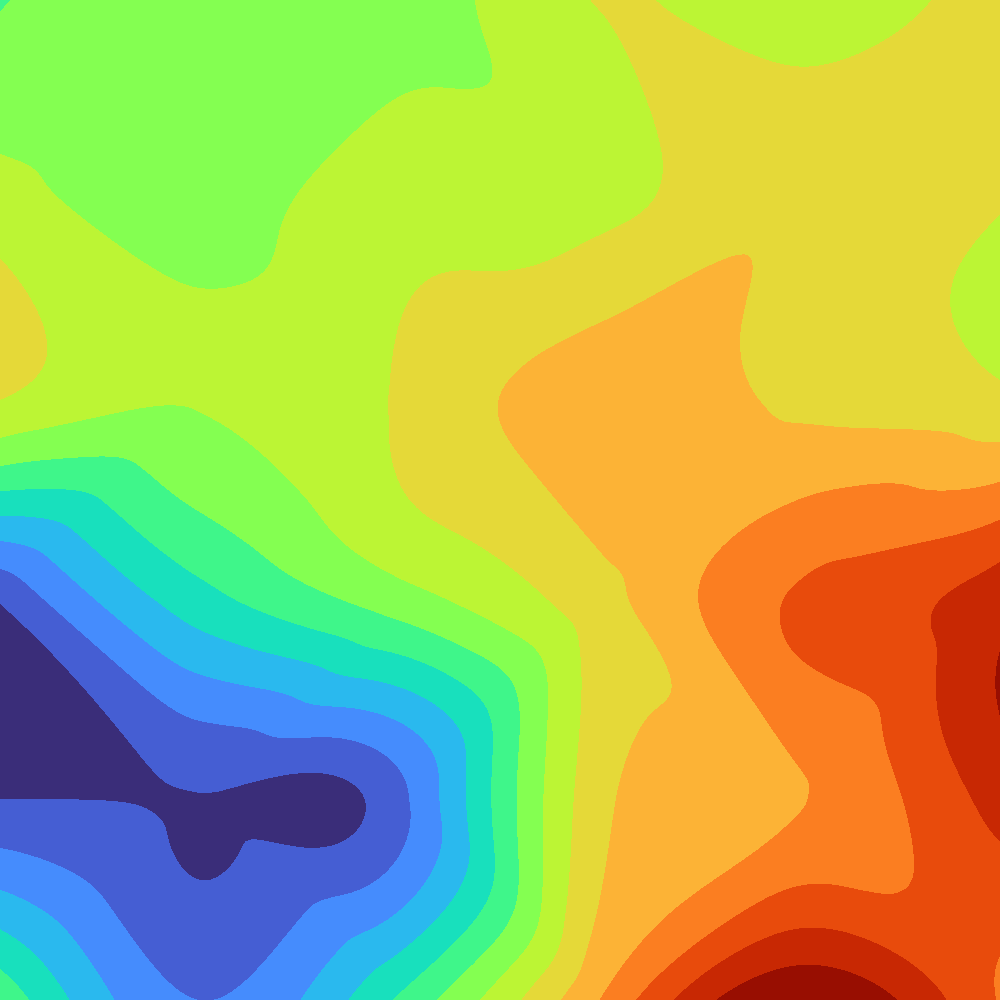
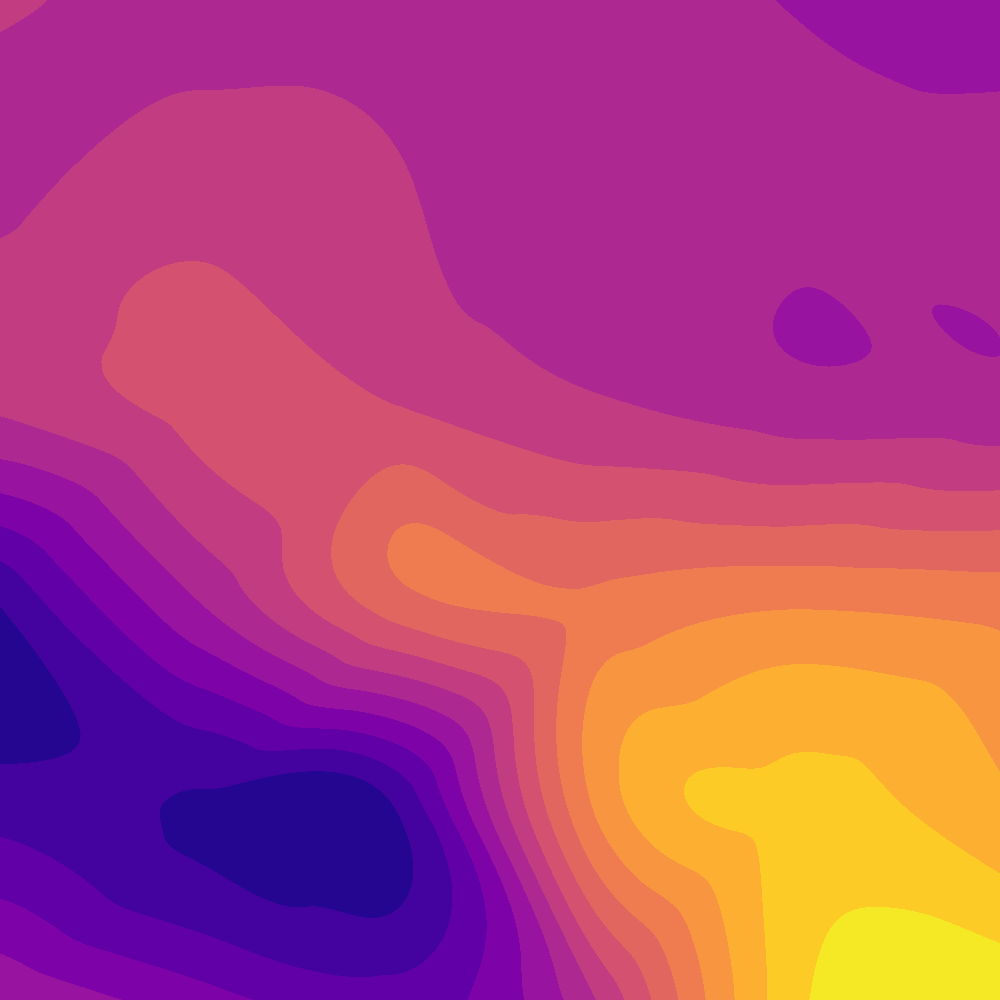
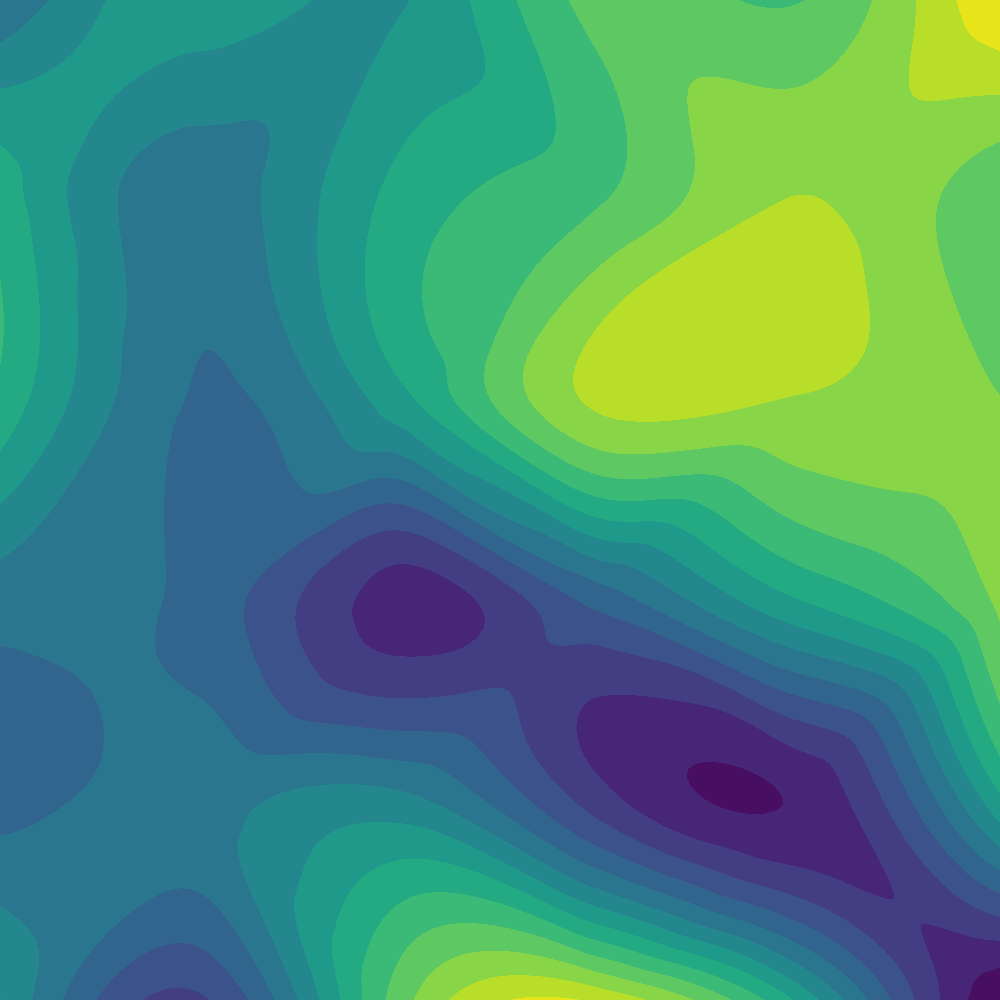

In [22]:
# 1. Compute site-level combined metrics
site_combined = pd.merge(siteMeans, siteChange, on=["location", "latitude", "longitude"])

s_min, s_max = site_combined["wind_speed_10m"].min(), site_combined["wind_speed_10m"].max()
d_min, d_max = site_combined["wind_derivative"].min(), site_combined["wind_derivative"].max()

norm_speed = (site_combined["wind_speed_10m"] - s_min) / (s_max - s_min + 1e-5)
norm_deriv = (site_combined["wind_derivative"] - d_min) / (d_max - d_min + 1e-5)

# Higher score = Strong winds + Low volatility (Stable & Fast)
site_combined["sweet_spot_score"] = norm_speed - norm_deriv

top5_df = site_combined.sort_values(by="sweet_spot_score", ascending=False).head(5)
print("Top 5 Optimal Wind Farm Sweet-Spot Sites in Alberta:")
display(top5_df)

# 2. Compute the Grid-level Sweet-Spot Surface across the 200x200 mesh and save layer
norm_grid_wind = (GRIDWIND - np.nanmin(GRIDWIND)) / (np.nanmax(GRIDWIND) - np.nanmin(GRIDWIND) + 1e-5)
norm_grid_change = (GRID_CHANGE - np.nanmin(GRID_CHANGE)) / (np.nanmax(GRID_CHANGE) - np.nanmin(GRID_CHANGE) + 1e-5)

GRID_SWEETSPOT = norm_grid_wind - norm_grid_change
save_contour_layer(GRIDLONG, GRIDLAT, GRID_SWEETSPOT, "wind_sweetspot_contour.png", "viridis")

# 3. Build Unified Multi-Layer Folium Map (Using reliable OpenStreetMap tiles)
unifiedMap = folium.Map(location=[54.5, -115.0], zoom_start=6, tiles="openstreetmap")

# 4. Add the 3 Contour Overlays
overlay_configs = [
    ("1. Mean Wind Speed (Turbo)", "wind_contour_overlay.png", False),
    ("2. Turbulence |dv/dt| (Plasma)", "wind_derivative_contour.png", False),
    ("3. Sweet-Spot Score (Viridis)", "wind_sweetspot_contour.png", True),
]

for layer_name, img_file, is_visible in overlay_configs:
    folium.raster_layers.ImageOverlay(
        name=layer_name,
        image=img_file,
        bounds=[[lat_min, lon_min], [lat_max, lon_max]],
        opacity=0.75,
        interactive=False,
        show=is_visible
    ).add_to(unifiedMap)

# 5. Add Major Alberta Cities Reference Layer
major_cities = {
    "Calgary": {"lat": 51.0447, "lon": -114.0719, "pop": "1.6M"},
    "Edmonton": {"lat": 53.5461, "lon": -113.4938, "pop": "1.5M"},
    "Red Deer": {"lat": 52.2681, "lon": -113.8111, "pop": "106K"},
    "Lethbridge": {"lat": 49.6935, "lon": -112.8447, "pop": "101K"},
    "Medicine Hat": {"lat": 50.0421, "lon": -110.6775, "pop": "63K"},
    "Grande Prairie": {"lat": 55.1691, "lon": -118.7979, "pop": "64K"},
    "Fort McMurray": {"lat": 56.7265, "lon": -111.3803, "pop": "68K"}
}

cities_group = folium.FeatureGroup(name="Major Alberta Cities", show=True).add_to(unifiedMap)

for city, data in major_cities.items():
    city_icon = folium.DivIcon(
        html=f"""
        <div style="
            font-family: sans-serif;
            font-size: 11px;
            font-weight: bold;
            color: #ffffff;
            background-color: rgba(0, 0, 0, 0.75);
            padding: 3px 7px;
            border-radius: 4px;
            border: 1px solid rgba(255,255,255,0.6);
            white-space: nowrap;
            box-shadow: 0 2px 4px rgba(0,0,0,0.4);
            transform: translate(-50%, -120%);">
            🏙️ {city}
        </div>
        """
    )
    folium.Marker(
        location=[data["lat"], data["lon"]],
        icon=city_icon,
        tooltip=folium.Tooltip(f"<b>{city}</b><br>Population: {data['pop']}")
    ).add_to(cities_group)

# 6. Add Interactive Station Markers (Highlighting Top 5 Sites)
stations_group = folium.FeatureGroup(name="Grid Stations & Top 5 Sites", show=True).add_to(unifiedMap)
top5_sites = set(top5_df["location"])

for _, row in site_combined.iterrows():
    is_top5 = row["location"] in top5_sites
    
    tooltip_html = (
        f"<div style='font-family: sans-serif; font-size: 12px; min-width: 160px;'>"
        f"<b>{row['location']} {'⭐ TOP 5 SITE' if is_top5 else ''}</b><hr style='margin: 4px 0;'>"
        f"<b>Coords:</b> {row['latitude']:.2f}°N, {row['longitude']:.2f}°W<br>"
        f"<b>Mean Wind (μ):</b> {row['wind_speed_10m']:.2f} m/s<br>"
        f"<b>Turbulence |dv/dt|:</b> {row['wind_derivative']:.2f} m/s²<br>"
        f"<b>Sweet-Spot Score:</b> <span style='color: #008060; font-weight: bold;'>{row['sweet_spot_score']:.3f}</span>"
        f"</div>"
    )
    
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=9 if is_top5 else 5,
        color="#00ffff" if is_top5 else "#333333",
        weight=2.5 if is_top5 else 1,
        fill=True,
        fill_color="#00ffff" if is_top5 else "#ffffff",
        fill_opacity=0.95 if is_top5 else 0.7,
        tooltip=folium.Tooltip(tooltip_html)
    ).add_to(stations_group)

# 7. Attach Colorbar Legend for Sweet-Spot Score
sweetspot_legend = cm.LinearColormap(
    colors=["#440154", "#3b528b", "#21918c", "#5ec962", "#fde725"],
    vmin=round(site_combined["sweet_spot_score"].min(), 2),
    vmax=round(site_combined["sweet_spot_score"].max(), 2),
    caption="Sweet-Spot Score (Normalized Speed − Normalized Volatility)"
)
unifiedMap.add_child(sweetspot_legend)

# 8. Add Layer Control widget
folium.LayerControl(collapsed=False).add_to(unifiedMap)

display(unifiedMap)